### Developing human heart - ligand-receptor communication in regions, subregions, ages and between cell types (mp_heart_dvlp04)

**Paper**: Lázár E, Mauron R, Andrusivová Ž, Foyer J, He M, Larsson L, Shakari N, Salas SM, Avenel C, Sariyar S, Hansen JN, Vicari M, Czarnewski P, Braun E, Li X, Bergmann O, Sylvén C, Lundberg E, Linnarsson S, Nilsson M, Sundström E, Adameyko I, Lundeberg J. *Spatiotemporal gene expression and cellular dynamics of the developing human heart.* Nat Genet. 2025 Nov;57(11):2756-2771. doi: [10.1038/s41588-025-02352-6](https://doi.org/10.1038/s41588-025-02352-6). PMID: 41162788; PMCID: PMC12597827.

Code: [github.com/rmauron/HDCA_heart_dev](https://github.com/rmauron/HDCA_heart_dev) (Zenodo 15912657) - Data: Mendeley [part 1](https://doi.org/10.17632/fhtb99mdzd.1) (Space Ranger, Cell Ranger, metadata) and [part 2](https://doi.org/10.17632/w65jtfsvpr.1) (Seurat RDS) - [Interactive viewer](https://hdcaheart.serve.scilifelab.se/web/index.html)

LIANA+ bivariate (spatial co-expression of ligand and receptor), cell-type-resolved sender -> receiver scores and the reference rank_aggregate, as in **mp_lymphoid04** / **mp_mouse_brain04**, **per region** (mp_heart_dvlp01), **per subregion** (mp_heart_dvlp03) and, new here, **per age group** (w6-w7, w8-w9, w10-w12).

**Question**: which ligand-receptor (LR) pairs are spatially active **in each region / subregion / developmental stage** of the heart, and **between which cell types** do they act? The paper predicted niche-level interactions with LIANA on the scRNA data (e.g. in the developing valves, epicardium and conduction system); here the spatial data are used directly.

#### Libs: **src/libs**

- **single_cell_lib**
  - Class **SingleCell**: generic Scanpy, Squidpy, cell2location and LIANA methods
  - **DEFAULT_PARAMS**
- **single_cell_heart_dvlp_lib** (new)
  - Class **SingleCellHeart(SingleCell)**: developing-heart methods (sections and ages, the paper's stereoscope proportions and spatial clusters, gene x age panels, regions vs the paper, temporal trends)
  - **HEART_PARAMS**, **HEART_LINEAGE** (31 cell types in 9 lineages), **HEART_GENES** (20 heart-development genes), **HEART_FILES** (one file registry per notebook: 'heart01' ... 'heart04')

| section | content |
|---|---|
| 1 | spots, regions, subregions, ages, abundances, signatures |
| 2 | spatial weights (Gaussian kernel per section, bandwidth in spot spacings) |
| 3 | LIANA bivariate: global Moran's R and local score of every LR pair |
| 4 | LR pairs enriched in each region and subregion |
| 5 | LR pairs enriched in each age group |
| 6 | between cell types: sender -> receiver (whole tissue) |
| 7 | between cell types inside each region / subregion / age group |
| 8 | reference LIANA (rank_aggregate) + cell-type co-localisation |
| 9 | consensus per region / subregion |
| 10 | tables |

**Data**: the 38 sections (69,115 spots), regions of **heart01_region_labels.tsv**, subregions of mp_heart_dvlp03 (**heart03_subregions/**), the scRNA reference (31 types). LR resource: LIANA **consensus** (human). Figures and tables have the prefix **heart04_**.

### Critique of the request and how it is handled

- **What a Visium LR score can mean.** A spot (55 um, 100 um spacing) holds ~10-30 cells of several types. The bivariate local score says that ligand and receptor are co-expressed **in a neighbourhood** (~2 rings, ~200 um), not that two cells signal.
- **38 sections.** The spatial kernel is built **per section** (block-diagonal: spots of different sections are never neighbours); global scores pool all sections.
- **Ages.** An LR pair ranked high in w10-w12 is higher in those sections than in the others; with 2-3 hearts per stage and different section planes (later hearts only partially captured), age contrasts mix development with anatomy. Read them together with the region contrasts.
- **Statistics.** Neighbouring spots are not independent: p-values are optimistic; groups and links are ranked by effect sizes (AUROC, score, z) with parameter cutoffs.
- **Between cell types.** Visium does not see cell types; the counts of each spot are split across cell types by abundance x reference signature (**calc_celltype_expr**). Signatures: cell2location reference (**means**) when the model exists, otherwise mean counts per cell type of the reference. Attribution follows the reference.
- **Uninformative pairs** (MHC, B2M, intracellular 'ligands'; **lr_display_exclude**) are computed but not listed. **R18** is excluded (**subregion_skip**).

## Loading packages

In [1]:
import os, sys
from pathlib import Path
from importlib.metadata import version
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import pandas as pd
import anndata as ad
import scanpy as sc
import gc

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import rcParams
rcParams['pdf.fonttype'] = 42          # editable text in PDFs
%config InlineBackend.print_figure_kwargs = {'bbox_inches': 'tight', 'dpi': 90}   # inline display only; files are saved at 300 dpi
import plotly.io as pio
pio.renderers.default = "notebook_connected"

ROOT0 = Path('/home/flavio/uv/cell_cell_communication')
ROOT_SRC = ROOT0 / 'src'
if str(ROOT_SRC) not in sys.path:
    sys.path.append(str(ROOT_SRC))

from libs.single_cell_heart_dvlp_lib import SingleCellHeart, HEART_PARAMS, HEART_LINEAGE, HEART_GENES, HEART_FILES
from libs.single_cell_lib import cmap_byr, cmap_lbwr
from libs.matplotlib_figure_style import apply_figure_style
from libs.Basic import create_dir

pd.set_option('display.max_colwidth', 120)
pd.set_option('display.width', 250)
pd.set_option('display.max_rows', 200)
print({p: version(p) for p in ['liana', 'scanpy', 'anndata', 'plotly']})

{'liana': '2.1.1', 'scanpy': '1.12.4', 'anndata': '0.13.4', 'plotly': '7.1.0'}


## Parameters

Class defaults (**DEFAULT_PARAMS** + **HEART_PARAMS**: LIANA values shared with mp_lymphoid04 / mp_mouse_brain04); files **HEART_FILES['inputs']** + **['heart04']**. Caching: every table method reads its file when it exists and **force=True**.

In [ ]:
force=True
verbose=False

apply_figure_style()
sch = SingleCellHeart(ROOT0, analysis='heart04')
ref_groupby, ref_symbol_col = sch.params['celltype_col'], sch.params['ref_symbol_col']
print(sch)
print({k: sch.params[k] for k in ['liana_resource', 'liana_bandwidth_spots', 'liana_nz_prop', 'lr_group_min_auroc', 'lr_display_exclude']})
sch.calc_df_files()

SingleCellHeart(project='heart_dvlp', adata=None, symbol_col='symbol', sample_col='section')
{'liana_resource': 'consensus', 'liana_bandwidth_spots': 1.1, 'liana_nz_prop': 0.05, 'lr_group_min_auroc': 0.65, 'lr_display_exclude': '(?i)^(HLA-|H2-)|^(B2M|LCK|GNAS|GNAI2|GNB1|ARF1|CALM[123]|RIMS1|SPTBN2|SHANK1|PTPN6)\\^'}


,key,root,name,path,exists
0,visium,data,hdca_heart_visium_38sections.h5ad,/home/flavio/uv/cell_cell_communication/heart_dvlp/data/hdca_heart_visium_38sections.h5ad,True
1,reference,data,hdca_heart_sc_reference.h5ad,/home/flavio/uv/cell_cell_communication/heart_dvlp/data/hdca_heart_sc_reference.h5ad,True
2,sections,data,heart_sections.tsv,/home/flavio/uv/cell_cell_communication/heart_dvlp/data/heart_sections.tsv,True
3,visium_raw,data,visium,/home/flavio/uv/cell_cell_communication/heart_dvlp/data/visium,True
4,bundle_sc,data,bundles/sc_reference,/home/flavio/uv/cell_cell_communication/heart_dvlp/data/bundles/sc_reference,True
5,bundle_st,data,bundles/st_clustering,/home/flavio/uv/cell_cell_communication/heart_dvlp/data/bundles/st_clustering,True
6,st_annotations,data,metadata/HDCA_heart_ST_annotations.csv,/home/flavio/uv/cell_cell_communication/heart_dvlp/data/metadata/HDCA_heart_ST_annotations.csv,True
7,hl_annotations,data,metadata/HDCA_heart_SC_annotations_HL_240115.csv,/home/flavio/uv/cell_cell_communication/heart_dvlp/data/metadata/HDCA_heart_SC_annotations_HL_240115.csv,True
8,dl_annotations,data,metadata/HDCA_heart_SC_annotations_DL_240204.csv,/home/flavio/uv/cell_cell_communication/heart_dvlp/data/metadata/HDCA_heart_SC_annotations_DL_240204.csv,True
9,stereoscope_hl,data,metadata/W.2023-09-25133054.715121_hl.tsv,/home/flavio/uv/cell_cell_communication/heart_dvlp/data/metadata/W.2023-09-25133054.715121_hl.tsv,True


### 1. Spots, regions, subregions, ages and cell-type abundances

**prepare_expression**: symbols as var_names, raw counts in **layers['counts']**, X = log1p(CP10k). Subregions: **run_subregions(force=True)** reads the cached subsets of mp_heart_dvlp03.

In [ ]:
df_regions = sch.read_tsv('region_labels', verbose=verbose)

source = df_regions['abundance_source'].iloc[0]
adata_map = sch.read_h5ad_slots('c2l_map', skip=('layers',)) if source == 'c2l' else sch.read_h5ad('visium', set_self=False)
adata_map = sch.remove_mt_genes(adata_map)
names_auto = sch.add_region_labels_from_table(df_regions, adata_map)

df_region_info = sch.read_region_info(source=source)
region_name = dict(zip(df_region_info.region_id, df_region_info.region_name)) if df_region_info is not None else names_auto
df_abund = sch.get_abundance(adata_map, source=source)

adata_ref = sch.filter_reference(sch.read_h5ad('reference', set_self=False))
df_sig = sch.reference_signatures_symbols(adata_ref, summary='means')       # genes (symbols) x cell types
print("signatures:", df_sig.attrs['source'], df_sig.shape)

adata_expr = sch.prepare_expression(adata_map)
subs, _ = sch.run_subregions(adata_expr, force=True, verbose=verbose)       # obs['sub_region_id'] from mp_heart_dvlp03
celltypes = [c for c in df_abund.columns if c in df_sig.columns]

df_sub03 = sch.read_tsv('subregion_table_heart03', verbose=verbose)
sub_supported = df_sub03.loc[df_sub03.status.str.startswith('supported'), 'sub_region_id'].tolist()

skip = set(sch.params['subregion_skip'])

groups = {'region': sch._groups(adata_expr, 'region_label', skip=skip),
          'subregion': sch._groups(adata_expr, 'sub_region_id'),
          'age_group': sch._groups(adata_expr, 'age_group')}

sections_rep = sch.representative_sections()

print(adata_expr.shape, '|', len(celltypes), 'cell types |', groups['region'].nunique(), 'regions |',
      groups['subregion'].nunique(), 'subregions (', len(sub_supported), 'supported in 03 ) |', groups['age_group'].nunique(), 'age groups')

signatures: c2l (21994, 31)
(69115, 21994) | 31 cell types | 33 regions | 163 subregions ( 123 supported in 03 ) | 3 age groups


### 2. Spatial weights

- Gaussian kernel **w = exp(-d^2 / 2bw^2)** with 

- **bw = liana_bandwidth_spots x spot spacing**, 
- built **per section**, 
- self weight 1, weights < **liana_cutoff** removed.

In [ ]:
force=True
verbose=False

df_w = sch.spatial_weights(adata_expr, force=force, verbose=verbose)
W = adata_expr.obsp['spatial_connectivities']
df_w.head(10)

,library,spacing_px,bandwidth_px,ring,n,weight,mean_neighbours_incl_self
0,V10A13-160_A1,581.0,639.1,0.0,1,1.000,16.7
1,V10A13-160_A1,581.0,639.1,1.0,6,0.660,16.7
2,V10A13-160_A1,581.0,639.1,1.7,6,0.288,16.7
3,V10A13-160_A1,581.0,639.1,2.0,6,0.190,16.7
4,V10A13-160_B1,582.0,640.2,0.0,1,1.000,15.8
5,V10A13-160_B1,582.0,640.2,1.0,6,0.660,15.8
6,V10A13-160_B1,582.0,640.2,1.7,6,0.288,15.8
7,V10A13-160_B1,582.0,640.2,2.0,6,0.190,15.8
8,V10A13-160_C1,581.0,639.1,0.0,1,1.000,16.9
9,V10A13-160_C1,581.0,639.1,1.0,6,0.660,16.9


In [23]:
W

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 1177011 stored elements and shape (69115, 69115)>

### 3. LIANA bivariate: spatially co-expressed LR pairs

**li.mt.bivariate** (resource **liana_resource**): 

- global **Moran's R** (permutation p, BH FDR) and the
- **local cosine** score of every pair at every spot, 
- with categories (1 = high-high) and local p-values. 
- Ligand and receptor (all complex subunits) in >= **liana_nz_prop** of the spots. 
- Cached in **root_result**.

In [ ]:
force=True
verbose=False

df_inter, adata_lr = sch.liana_bivariate(adata_expr, force=force, verbose=verbose)
df_lr_sig = sch.lr_significant(df_inter)
print(f"LR pairs tested: {len(df_inter)}; Moran's R > 0 at FDR <= {sch.params['liana_fdr']}: {len(df_lr_sig)}")

cols = ['ligand', 'receptor', 'ligand_means', 'ligand_props',
       'receptor_means', 'receptor_props', 'morans', 'morans_pvals',
       'mean', 'std', 'morans_fdr']
df_lr_sig['CV'] = df_lr_sig['std'] / df_lr_sig['mean']
cols = ['ligand', 'receptor', 'ligand_props', 'receptor_props', 'morans', 'morans_fdr', 'CV']
df_lr_sig[cols].head(20).round(3)

LR pairs tested: 1089; Moran's R > 0 at FDR <= 0.05: 945


/tmp/ipykernel_459134/3395415028.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy


,ligand,receptor,ligand_props,receptor_props,morans,morans_fdr,CV
interaction,,,,,,,
THBS2^NOTCH3,THBS2,NOTCH3,0.320,0.375,0.326,0.0,0.875
SPARC^FGFR1,SPARC,FGFR1,0.917,0.420,0.258,0.0,0.382
JAG1^NOTCH3,JAG1,NOTCH3,0.293,0.375,0.257,0.0,0.878
PLAT^LRP1,PLAT,LRP1,0.189,0.417,0.246,0.0,1.093
COL1A2^CD44,COL1A2,CD44,0.942,0.094,0.224,0.0,0.943
COL1A1^CD44,COL1A1,CD44,0.958,0.094,0.217,0.0,0.938
COL1A1^DDR2,COL1A1,DDR2,0.958,0.161,0.217,0.0,0.632
GPC3^LRP1,GPC3,LRP1,0.345,0.417,0.217,0.0,0.782
FN1^SDC2,FN1,SDC2,0.881,0.286,0.213,0.0,0.549


In [26]:
# np.array(df_lr_sig.columns)

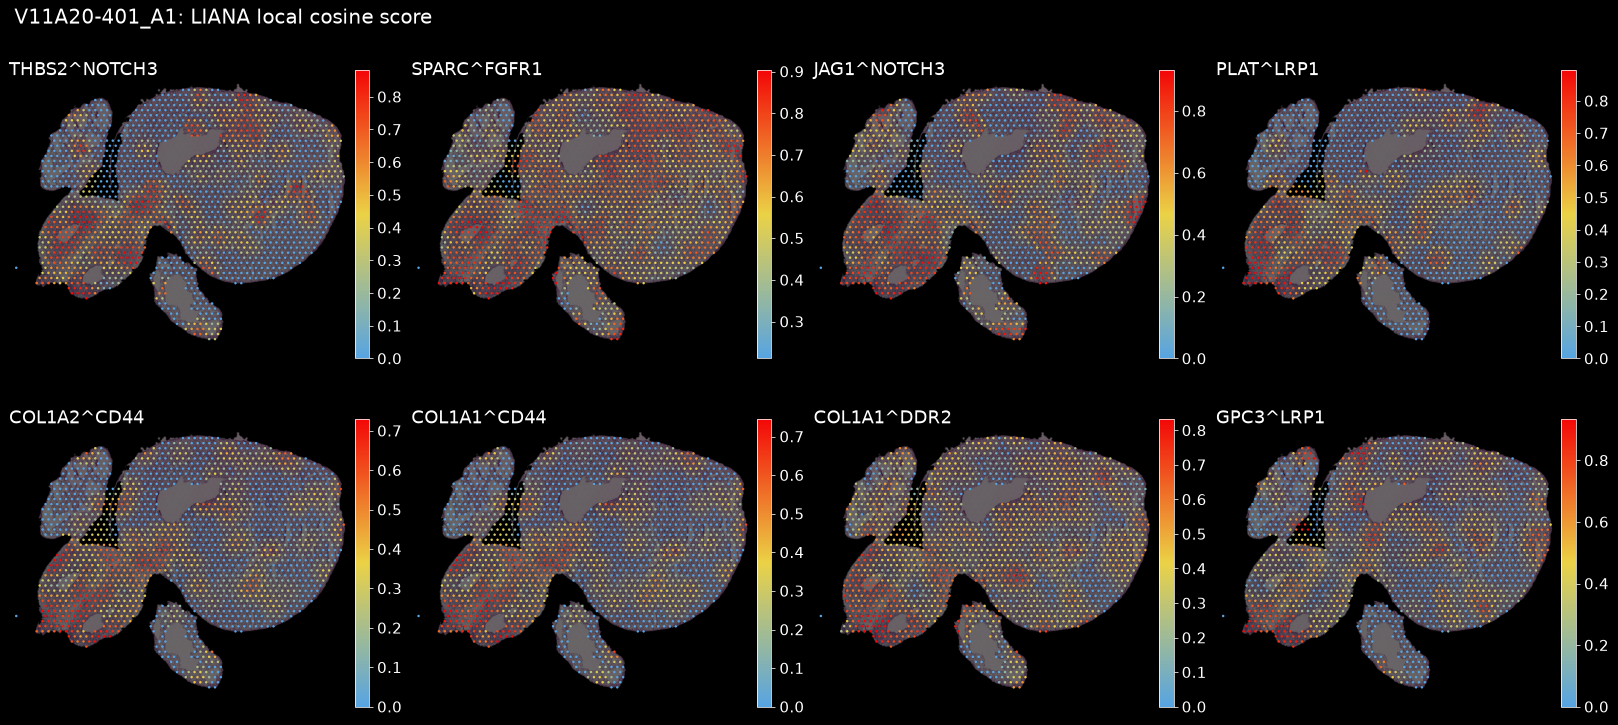

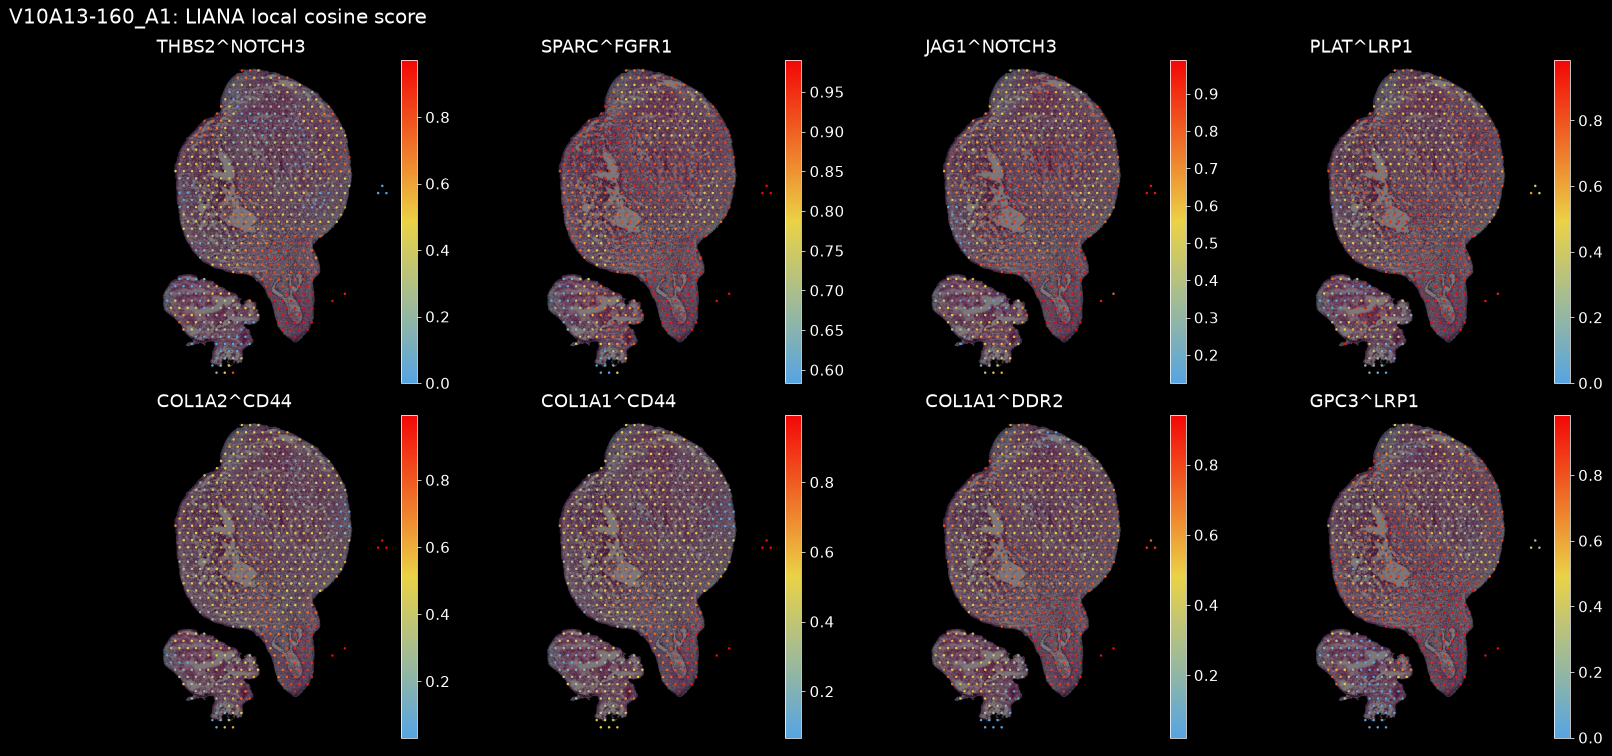

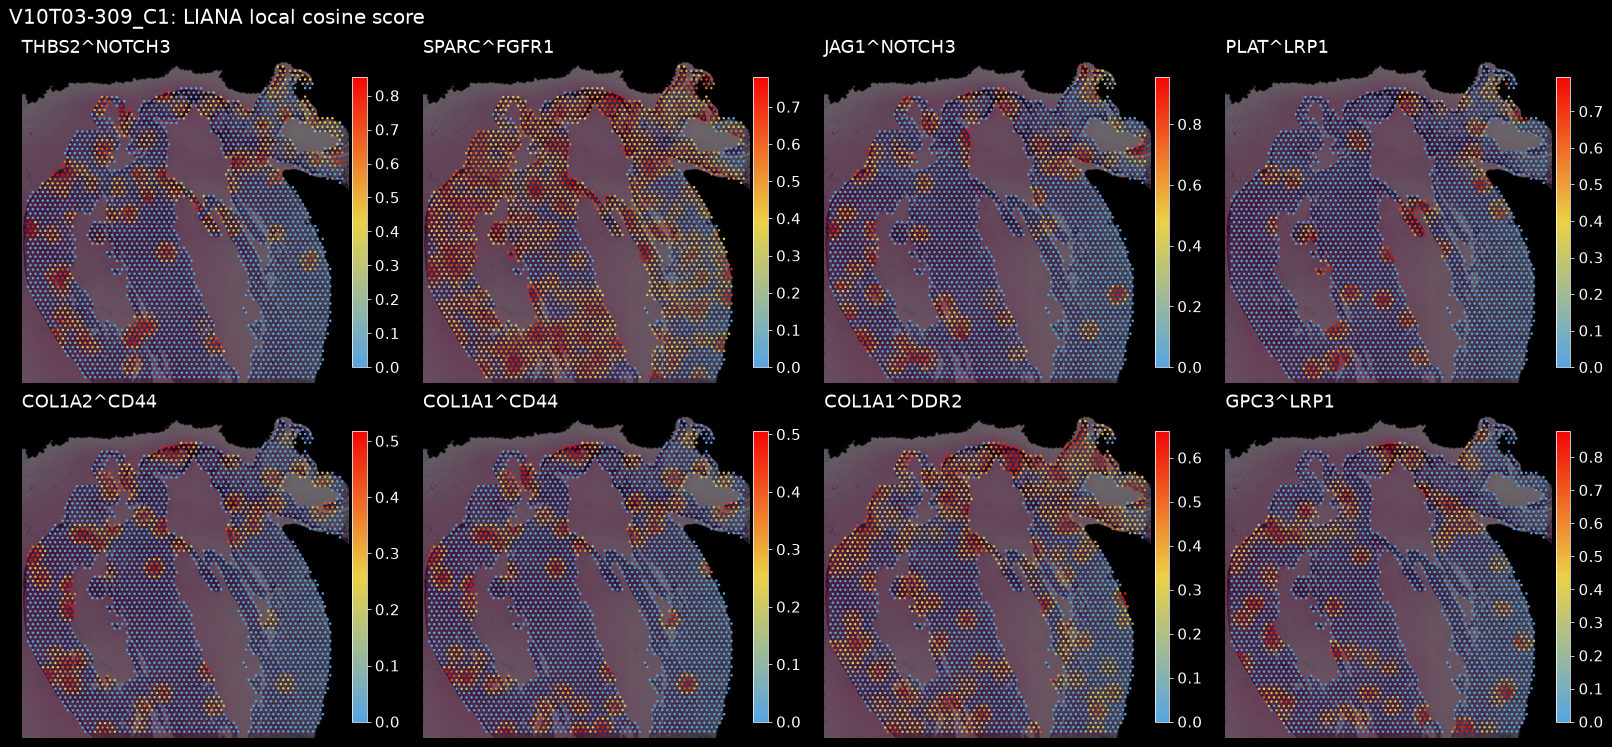

In [ ]:
force=True
verbose=False

lr_show = sch._lr_display(df_lr_sig.index)[:8]

for lib in [sch.params['library_main'], sections_rep[0], sections_rep[-1]]:
    fig = sch.plot_lr_spatial(adata_lr, adata_expr, lr_show, library_id=lib, ncols=3, figsize=(18, 8), 
                              fontsize_title=14, fontsize_suptitle=16, fontsize_colorbar=12, 
                              fname='fig_lr_top', force=force, verbose=verbose)
    plt.show()

### 4. LR pairs enriched in each region and subregion

**calc_df_lr_by_group**: per group, the local score of every significant pair in the group vs the rest of the tissue: **AUROC**, mean local score in / out, fraction of high-high spots in / out; **enriched** = AUROC >= **lr_group_min_auroc** and more high-high spots than elsewhere.

In [ ]:
force=True
verbose=False
df_lr_region = sch.calc_df_lr_by_group(adata_lr, groups['region'], df_lr_sig.index, fname='lr_by_region', force=force, verbose=verbose)
df_lr_sub = sch.calc_df_lr_by_group(adata_lr, groups['subregion'], df_lr_sig.index, fname='lr_by_subregion', force=force, verbose=verbose)

df_n = pd.DataFrame({'n_enriched': df_lr_region[df_lr_region.enriched].groupby('group').size()}) \
         .reindex(sorted(groups['region'].dropna().unique())).fillna(0).astype(int)
df_n['region_name'] = df_n.index.map(region_name)
df_n['top_lr'] = sch.calc_df_lr_group_top(df_lr_region)
df_n

,n_enriched,region_name,top_lr
group,,,
R00,78,Trabecular ventricular myocardium and endocardium,"HAPLN1^ADGRA2 (0.78), FN1^NT5E (0.76), FN1^ITGA9 (0.73), CTHRC1^FZD6 (0.73), VCAN^ITGB1 (0.73)"
R01,0,"Ventricular myocardium at the lumen, MetAct_vCM_2 (low genes)",NaN
R02,122,"Compact ventricular myocardium, depth tier 3","LGALS3^ENG (0.80), BMP7^ENG (0.77), NPPA^NPR3 (0.76), BSG^SLC16A1 (0.76), BMP10^ENG (0.76)"
R03,13,"Compact ventricular myocardium, depth tier 4, RV-rich","S100A4^ERBB2 (0.68), THBS4^CD36 (0.68), LPL^VLDLR (0.67), VEGFA^ITGB1 (0.66), LAMA2^RPSA (0.66)"
R04,0,"Ventricular myocardium near endocardium and AV plane, low depth",NaN
R05,2,"Ventricular myocardium near endocardium, depth tier 2",NaN
R06,131,"Subepicardial and perivascular tissue, mixed, low depth","HAPLN1^ADGRA2 (0.83), COL9A2^ITGA9_ITGB1 (0.79), EDIL3^ITGAV (0.79), INHBA^BAMBI (0.78), COL9A3^ITGA9_ITGB1 (0.77)"
R07,51,"Compact ventricular myocardium, depth tier 4, LV-rich","S100A4^ERBB2 (0.73), LPL^VLDLR (0.72), VEGFA^ITGB1 (0.72), THBS4^CD36 (0.71), LAMA2^RPSA (0.71)"
R08,2,"Compact ventricular myocardium, depth tier 5","JAG1^NOTCH3 (0.69), JAG2^NOTCH3 (0.67)"


In [ ]:
force=True
verbose=False
fig = sch.plotly_lr_group_heatmap(df_lr_region, n_per_group=3, group_names=region_name, height=950, width=1800, fontsize_title=22,
                                  fontsize_xticks=13, fontsize_yticks=13, fontsize_colorbar=14, fontsize_hover=14,
                                  fname='fig_lr_region_hm', force=force, verbose=verbose)
fig.show()

The top enriched pair of each region on the w8 section (region outlined):

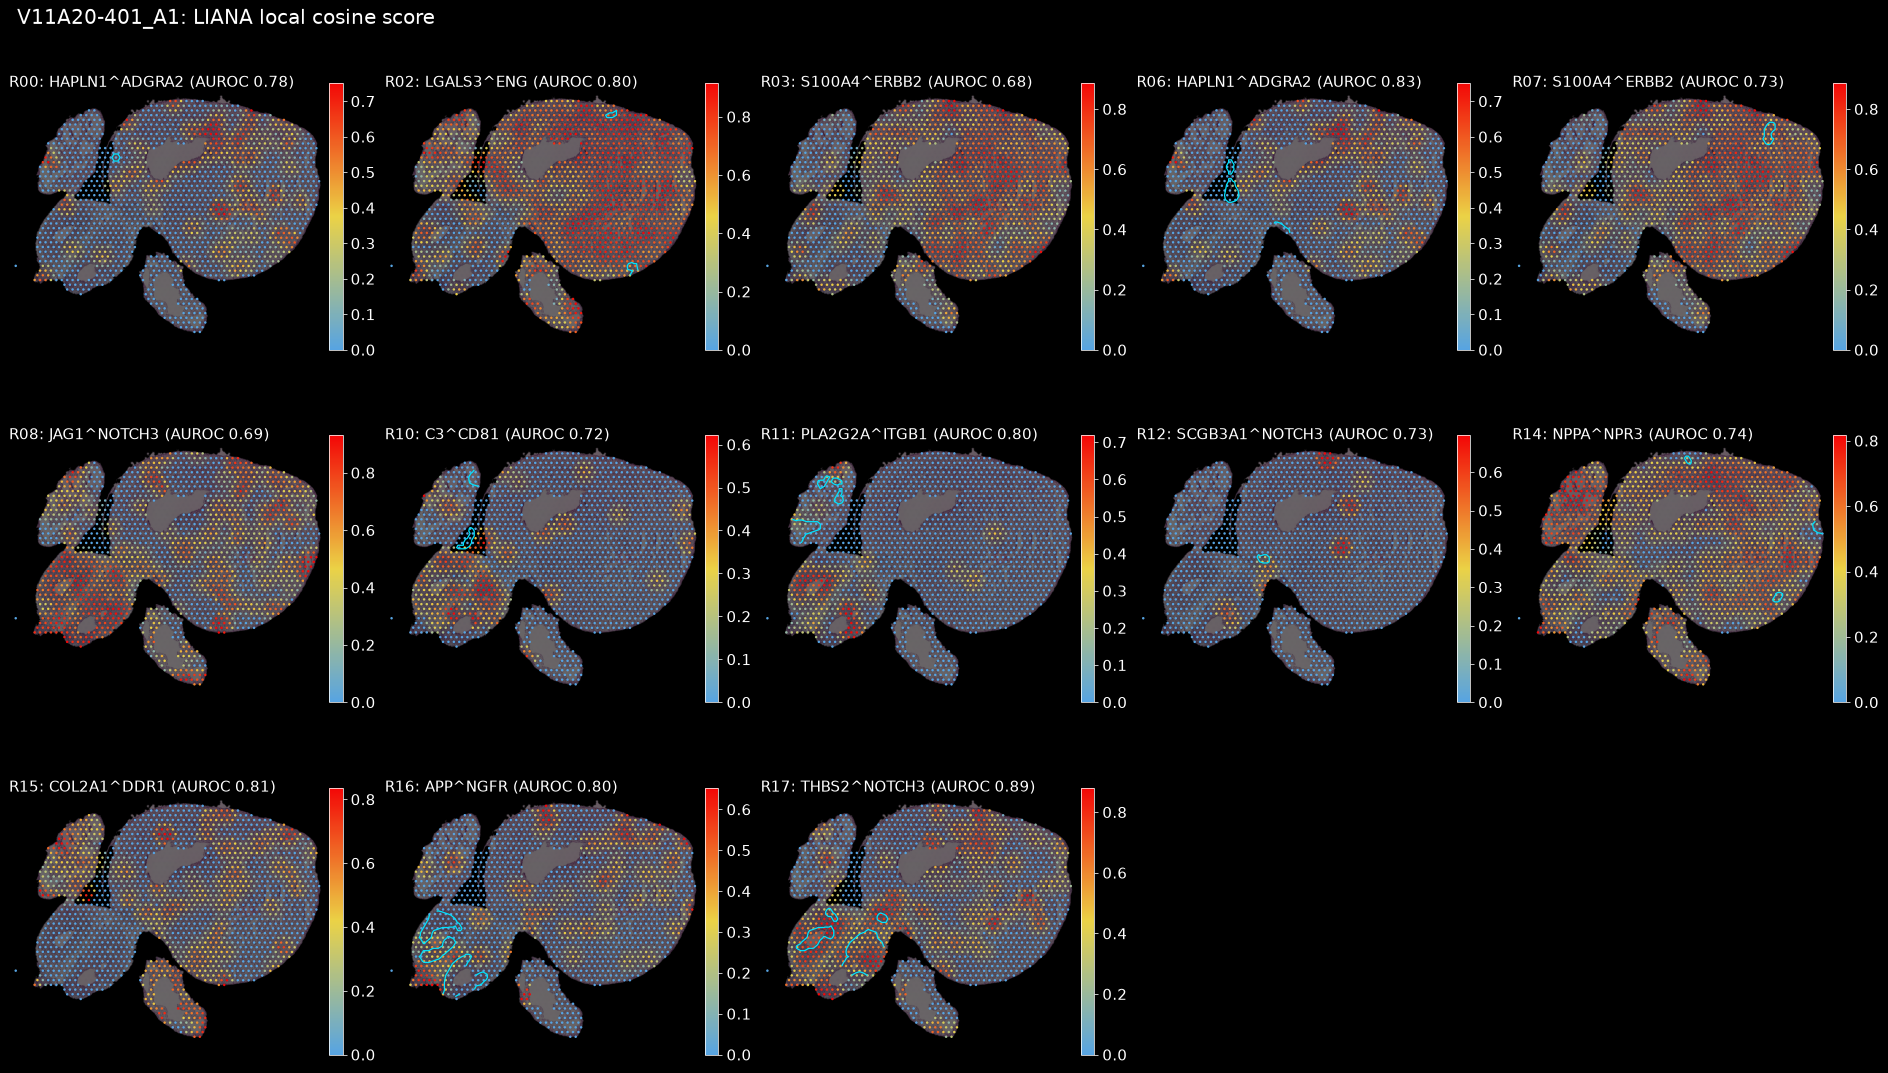

In [ ]:
force=True
verbose=False
top1 = df_lr_region[df_lr_region.enriched & df_lr_region.interaction.isin(set(sch._lr_display(df_lr_region.interaction.unique())))] \
         .groupby('group').head(1)
reg_lab = adata_expr.obs['region_label'].astype(str).values
ncols = 5
nrows = -(-len(top1) // ncols)
lib = sch.params['library_main']
fig = sch.plot_lr_spatial(adata_lr, adata_expr, list(top1.interaction), library_id=lib, ncols=ncols, figsize=(4.2 * ncols, 4 * nrows),
                          titles=[f"{g}: {i} (AUROC {a:.2f})" for g, i, a in zip(top1.group, top1.interaction, top1.auroc)],
                          outlines=[reg_lab == g for g in top1.group], fontsize_title=12, fontsize_suptitle=16, fontsize_colorbar=12,
                          fname='fig_lr_regions', force=force, verbose=verbose)
plt.show()

Subregions: the **supported** subregions of mp_heart_dvlp03.

In [ ]:
force=True
verbose=False
df_n_sub = df_lr_sub[df_lr_sub.group.isin(sub_supported)]
print(f"{df_n_sub[df_n_sub.enriched].group.nunique()} of {len(sub_supported)} supported subregions have >= 1 enriched LR pair")
fig = sch.plotly_lr_group_heatmap(df_lr_sub, n_per_group=2, groups=[g for g in sub_supported if g in set(df_lr_sub.group)],
                                  height=1400, width=1900, fontsize_title=22, fontsize_xticks=13, fontsize_yticks=13,
                                  fontsize_colorbar=14, fontsize_hover=14, fname='fig_lr_sub_hm', force=force, verbose=verbose)
fig.show()

49 of 123 supported subregions have >= 1 enriched LR pair


### 5. LR pairs by age group

The same test with the three developmental stages as groups (w6-w7: 11 sections, w8-w9: 12, w10-w12: 15). Stage contrasts are much weaker than region contrasts: on this data no pair reaches **lr_group_min_auroc** (0.65; maximum about 0.64), because every stage contains all tissue compartments. The pairs are therefore **ranked** by AUROC per stage (descriptive, no cutoff), with the region of each pair's strongest regional enrichment: an age-ranked pair often reflects a compartment that is larger at that stage (e.g. cushion and outflow-tract matrix early, coronary and fibroblast tissue late) as much as a change of signalling within one compartment.

In [ ]:
force=True
verbose=False
df_lr_age = sch.calc_df_lr_by_group(adata_lr, groups['age_group'], df_lr_sig.index, fname='lr_by_age', force=force, verbose=verbose)
print(df_lr_age.groupby('group').auroc.describe().round(3))
best_region = df_lr_region.sort_values('auroc', ascending=False).drop_duplicates('interaction').set_index('interaction')['group']
keep = set(sch._lr_display(df_lr_age.interaction.unique()))
df_age_top = df_lr_age[df_lr_age.interaction.isin(keep)].sort_values('auroc', ascending=False).groupby('group').head(10).copy()
df_age_top['best_region'] = df_age_top.interaction.map(best_region)
df_age_top['best_region_name'] = df_age_top.best_region.map(region_name)
df_age_top[['group', 'interaction', 'auroc', 'mean_in', 'mean_out', 'hh_frac_in', 'hh_frac_out', 'best_region', 'best_region_name']].round(3)

         count   mean    std    min    25%    50%    75%    max
group                                                          
w10-w12  945.0  0.466  0.031  0.384  0.447  0.465  0.485  0.609
w6-w7    945.0  0.519  0.030  0.414  0.499  0.523  0.538  0.603
w8-w9    945.0  0.533  0.039  0.381  0.508  0.531  0.559  0.639


,group,interaction,auroc,mean_in,mean_out,hh_frac_in,hh_frac_out,best_region,best_region_name
1891,w8-w9,ANGPT1^ITGB1,0.636,0.313,0.194,0.135,0.070,R14,"Compact ventricular myocardium, depth tier 2, microvascular"
1892,w8-w9,BMP7^ACTR2,0.636,0.425,0.293,0.120,0.059,R02,"Compact ventricular myocardium, depth tier 3"
1893,w8-w9,BSG^SLC16A1,0.636,0.622,0.498,0.188,0.115,R02,"Compact ventricular myocardium, depth tier 3"
1894,w8-w9,CCN2^ERBB4,0.635,0.341,0.218,0.079,0.033,R02,"Compact ventricular myocardium, depth tier 3"
1895,w8-w9,MDK^NCL,0.631,0.829,0.762,0.213,0.089,R02,"Compact ventricular myocardium, depth tier 3"
1896,w8-w9,BMP7^PTPRK,0.628,0.356,0.237,0.071,0.037,R02,"Compact ventricular myocardium, depth tier 3"
1897,w8-w9,ADAM10^CADM1,0.627,0.389,0.268,0.092,0.045,R02,"Compact ventricular myocardium, depth tier 3"
1899,w8-w9,NCAM1^ROBO1,0.622,0.415,0.299,0.155,0.052,R06,"Subepicardial and perivascular tissue, mixed, low depth"
1900,w8-w9,ADAM17^ITGB1,0.621,0.367,0.273,0.121,0.060,R02,"Compact ventricular myocardium, depth tier 3"
1901,w8-w9,VCAN^ITGB1,0.620,0.745,0.653,0.272,0.156,R06,"Subepicardial and perivascular tissue, mixed, low depth"


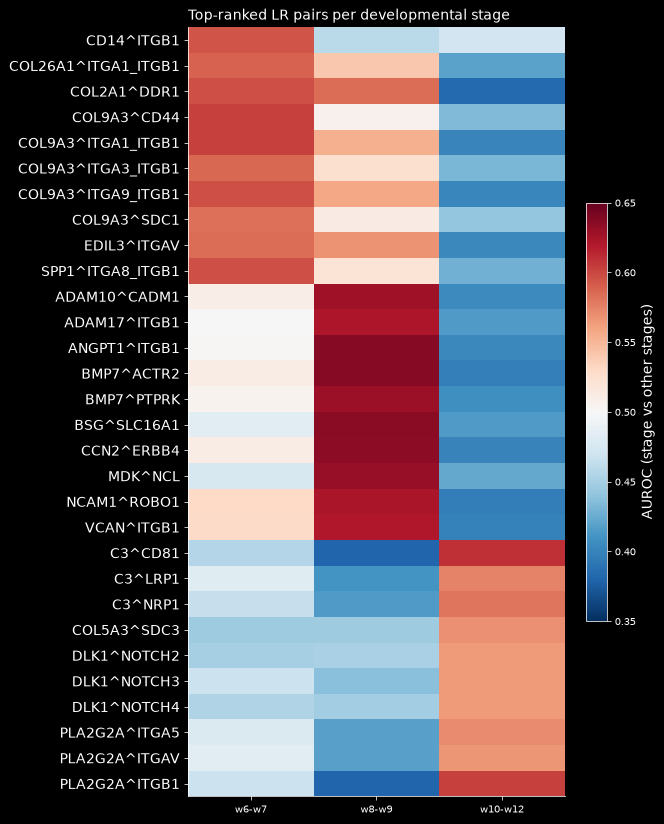

In [12]:
# AUROC of the top-ranked pairs of every stage in all three stages (0.5 = as in the other stages)
fig = sch.plot_lr_auroc_by_age_group(df_lr_age, df_age_top, fname='heart04_lr_by_age_group_top.png', force=force, verbose=verbose)
plt.show()

### 6. Between cell types: sender -> receiver (whole tissue)

**calc_celltype_expr**: counts of every spot split across cell types (abundance x signature), log1p(CP10k). **calc_df_celltype_lr** for the **lr_top_n** significant pairs with the highest Moran's R: **score[A, B] = mean over spots of (W_norm · L_A) x R_B**; null: receptor spots permuted (**c2l_lr_n_perms**) -> z; **score_share** = share of the pair's total over all A, B.

In [ ]:
force=True
verbose=False
df_lr_top = df_lr_sig.head(sch.params['lr_top_n'])[['ligand', 'receptor']]
genes = sorted({s for e in list(df_lr_top.ligand) + list(df_lr_top.receptor) for s in e.split('_')})
E, genes_E, celltypes_E = sch.calc_celltype_expr(adata_expr, df_abund.loc[adata_expr.obs_names, celltypes], df_sig[celltypes], genes)
print('E (spots x cell types x genes):', E.shape, '| LR genes without signature:', sorted(set(genes) - set(genes_E)))
df_ct, df_group_ct = sch.calc_df_celltype_lr(E, genes_E, celltypes_E, df_lr_top, W, groups=groups, force=force, verbose=verbose)
df_best = df_ct[df_ct.rank_in_lr == 1].set_index('interaction')
df_best = df_best.loc[[i for i in df_lr_top.index if i in df_best.index]]
print(df_ct.interaction.nunique(), 'LR pairs x', len(celltypes_E), 'x', len(celltypes_E), 'sender-receiver')
df_best[['sender', 'receiver', 'score', 'score_share', 'z']].head(20).round(3)

E (spots x cell types x genes): (69115, 31, 88) | LR genes without signature: []
100 LR pairs x 31 x 31 sender-receiver


,sender,receiver,score,score_share,z
interaction,,,,,
THBS2^NOTCH3,OFT_SMC,OFT_SMC,0.206,0.236,206.705
SPARC^FGFR1,OFT_SMC,OFT_SMC,0.318,0.063,172.642
JAG1^NOTCH3,OFT_SMC,OFT_SMC,0.129,0.202,208.040
PLAT^LRP1,OFT_SMC,OFT_SMC,0.103,0.200,164.995
COL1A2^CD44,OFT_SMC,OFT_SMC,0.123,0.085,97.827
COL1A1^CD44,OFT_SMC,OFT_SMC,0.123,0.083,97.750
COL1A1^DDR2,OFT_SMC,OFT_SMC,0.128,0.054,113.707
GPC3^LRP1,OFT_SMC,OFT_SMC,0.077,0.096,170.027
FN1^SDC2,OFT_SMC,OFT_SMC,0.255,0.122,162.785


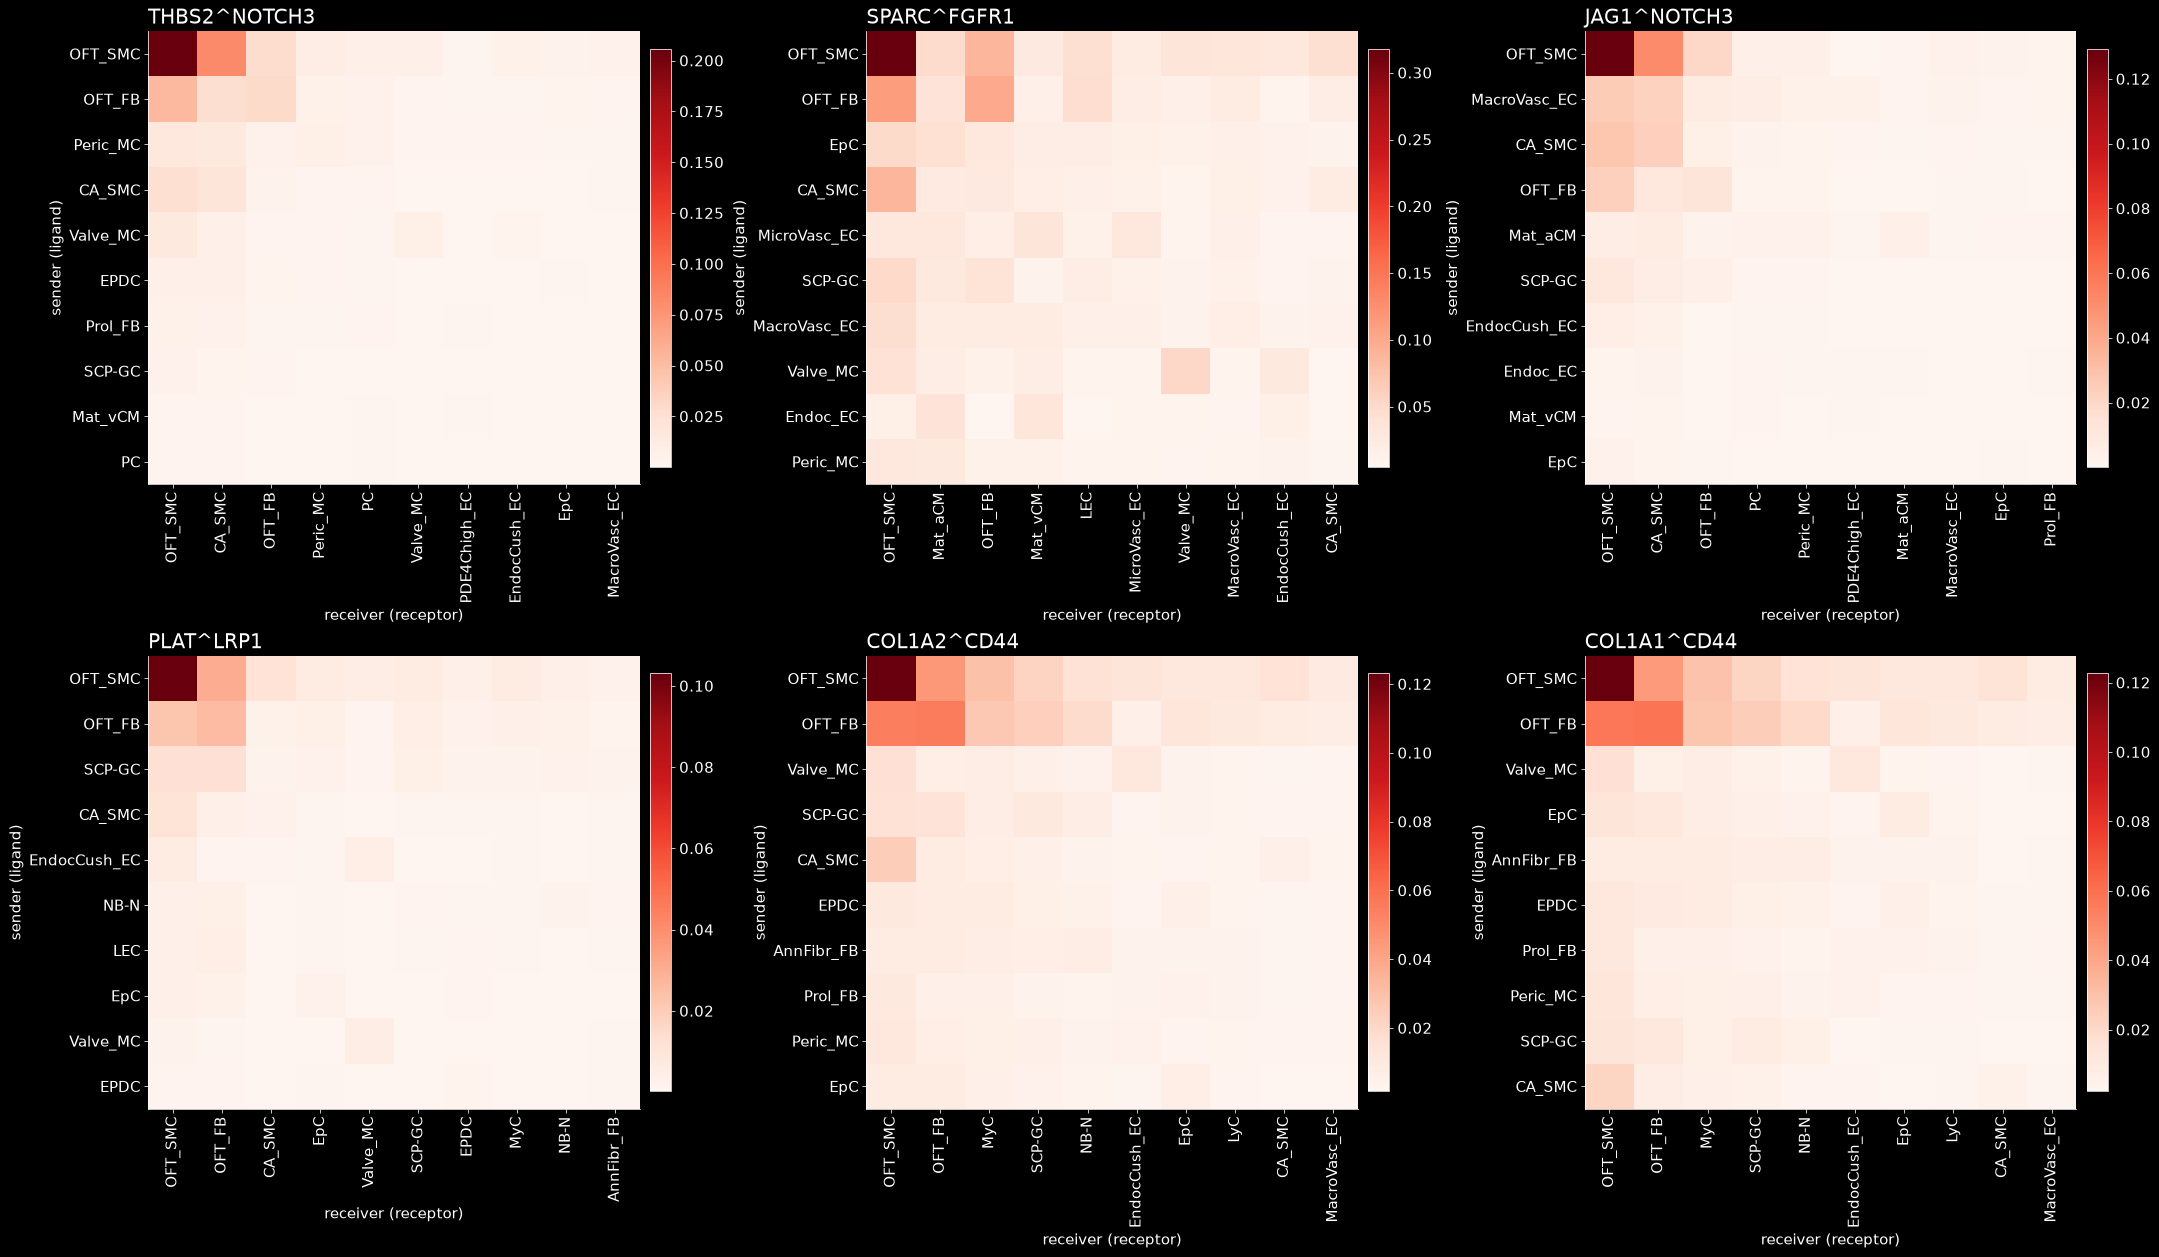

In [ ]:
force=True
verbose=False
lr_panels = sch._lr_display(df_best.index)[:6]
fig = sch.plot_sender_receiver_heatmaps(df_ct, lr_panels, n_top=10, ncols=3, panel_size=(8, 7.0), fontsize_title=16, fontsize_ticks=12,
                                        fontsize_label=12, fontsize_colorbar=12, fname='fig_sender_recv', force=force, verbose=verbose)
plt.show()

### 7. Between cell types inside each region / subregion / age group

The same score over the spots of each group; receptor spots permuted **within** the group (**c2l_lr_group_n_perms**) -> z; **ratio** = group score / whole-tissue score. **calc_df_group_celltype_links**: per group and sender -> receiver, the number of LR pairs with z >= **c2l_lr_min_z** and ratio >= 1.

In [ ]:
force=True
verbose=False
df_links = sch.calc_df_group_celltype_links(df_group_ct, force=force, verbose=verbose)
lev = df_group_ct.drop_duplicates('group').set_index('group').level
df_links_reg = df_links[df_links.group.map(lev) == 'region']
df_links_reg[~df_links_reg.self_link].groupby('group').head(2)[['group', 'link', 'n_lr', 'lr']]

,group,link,n_lr,lr
1,R00,Valve_MC -> EndocCush_EC,82,"LGALS1^ITGB1, COL1A1^ITGA9_ITGB1, COL1A2^ITGA9_ITGB1, VCAN^ITGB1, CD99^CD81, SPARC^FGFR1"
3,R00,EndocCush_EC -> Valve_MC,62,"VCAN^ITGB1, HSPG2^ITGB1, MDK^LRP1, CD99^CD81, HSPG2^LRP1, TGM2^ITGB1"
101,R01,PDE4Chigh_EC -> MicroVasc_EC,23,"LGALS1^ITGB1, CD99^CD81, HSPG2^ITGB1, NID1^ITGB1, TIMP2^ITGB1, SPARC^FGFR1"
102,R01,Int_FB -> MicroVasc_EC,23,"COL1A1^ITGA1_ITGB1, COL3A1^ITGA1_ITGB1, COL1A2^ITGA1_ITGB1, COL6A3^ITGA1_ITGB1, COL6A1^ITGA1_ITGB1, PTN^SDC3"
440,R02,Endoc_EC -> Mat_vCM,21,"TGM2^ITGB1, COL18A1^GPC1, LGALS1^ITGB1, HSPG2^ITGB1, FN1^ITGAV_ITGB1, VCAN^ITGB1"
441,R02,Prol_FB -> Mat_vCM,21,"LGALS1^ITGB1, COL1A1^ITGA9_ITGB1, COL1A2^ITGA9_ITGB1, NID1^ITGB1, FN1^ITGAV_ITGB1, TIMP2^ITGB1"
512,R03,PDE4Chigh_EC -> MicroVasc_EC,32,"CD99^CD81, LGALS1^ITGB1, NID1^ITGB1, VEGFA^ITGB1, TIMP2^ITGB1, SPARC^FGFR1"
515,R03,Mat_vCM -> MicroVasc_EC,20,"TGM2^ITGB1, VEGFA^ITGB1, CD99^CD81, VCAN^ITGB1, NID1^ITGB1, TIMP2^ITGB1"
678,R04,PDE4Chigh_EC -> Mat_vCM,2,"LGALS1^ITGB1, CD99^CD81"
679,R04,Mat_vCM -> Int_FB,2,"MDK^SDC2, PSAP^LRP1"


In [ ]:
force=True
verbose=False
fig = sch.plotly_group_celltype_links(df_links_reg, n_links=30, group_names=region_name, groups=sorted(df_links_reg.group.unique()),
                                      height=1000, width=1600, fontsize_title=22, fontsize_xticks=14, fontsize_yticks=14,
                                      fontsize_colorbar=14, fontsize_hover=14, fname='fig_links_region', force=force, verbose=verbose)
fig.show()

In [ ]:
force=True
verbose=False
df_links_sub = df_links[df_links.group.isin(sub_supported)]
groups_sub = [g for g in sub_supported if g in set(df_links_sub.group)]
fig = sch.plotly_group_celltype_links(df_links_sub, n_links=30, groups=groups_sub, width=1600, height=1300, fontsize_title=22,
                                      fontsize_xticks=13, fontsize_yticks=13, fontsize_colorbar=14, fontsize_hover=14,
                                      fname='fig_links_sub', force=force, verbose=verbose)
fig.show()

In [18]:
# age groups: top sender -> receiver links per stage
df_links_age = df_links[df_links.group.map(lev) == 'age_group']
df_links_age[~df_links_age.self_link].groupby('group').head(6)[['group', 'link', 'n_lr', 'lr']]

,group,link,n_lr,lr
3721,w10-w12,OFT_FB -> OFT_SMC,73,"SPARC^FGFR1, MDK^LRP1, LGALS1^ITGB1, FBN1^ITGB1, COL1A1^ITGA9_ITGB1, COL1A2^ITGA9_ITGB1"
3722,w10-w12,CA_SMC -> OFT_SMC,54,"SPARC^FGFR1, LGALS1^ITGB1, FN1^SDC2, FBN1^ITGB1, COL1A2^ITGA9_ITGB1, COL1A1^ITGA9_ITGB1"
3724,w10-w12,OFT_SMC -> CA_SMC,44,"THBS2^NOTCH3, LGALS1^ITGB1, CXCL12^ITGB1, FBN1^ITGB1, COL1A1^ITGA1_ITGB1, COL1A2^ITGA1_ITGB1"
3725,w10-w12,OFT_SMC -> OFT_FB,43,"MDK^LRP1, SPARC^FGFR1, CXCL12^ITGB1, CALR^LRP1, COL1A1^DDR2, COL3A1^DDR2"
3726,w10-w12,MacroVasc_EC -> OFT_SMC,26,"HSPG2^ITGB1, HSPG2^LRP1, HSPG2^FGFR1, CXCL12^ITGB1, SPARC^FGFR1, FBN1^ITGB1"
3727,w10-w12,Valve_MC -> OFT_SMC,23,"POSTN^PTK7, PTN^SDC2, COL1A1^ITGA1_ITGB1, COL1A2^ITGA1_ITGB1, MMP2^FGFR1, PTN^SDC3"
3806,w6-w7,OFT_SMC -> CA_SMC,27,"LGALS1^ITGB1, CXCL12^ITGB1, COL1A1^ITGA1_ITGB1, COL1A2^ITGA1_ITGB1, FN1^SDC2, JAG1^NOTCH3"
3807,w6-w7,CA_SMC -> OFT_SMC,24,"LGALS1^ITGB1, FN1^SDC2, FN1^ITGAV_ITGB1, COL1A2^ITGA1_ITGB1, JAG1^NOTCH3, COL1A1^ITGA1_ITGB1"
3808,w6-w7,Endoc_EC -> Mat_vCM,19,"TGM2^ITGB1, FN1^ITGAV_ITGB1, LGALS1^ITGB1, VCAN^ITGB1, HSPG2^ITGB1, CALR^ITGAV"
3809,w6-w7,Mat_vCM -> Endoc_EC,15,"TGM2^ITGB1, VEGFA^ITGB1, VCAN^ITGB1, BMP10^ENG, NID1^ITGB1, COL4A2^ITGA9_ITGB1"


### 8. Reference LIANA (rank_aggregate) + cell-type co-localisation

**liana_rank_aggregate_reference**: rank_aggregate (CellPhoneDB, Connectome, log2FC, NATMI, SCA, CellChat-like) on the reference (up to **ref_lr_cells_per_type** cells per type; symbols from **var['symbol']**). Non-spatial, so each source -> target is annotated with **co-localisation** (**calc_df_celltype_coloc**). Specific and strong = specificity_rank <= **ref_lr_spec_rank** and magnitude_rank <= **ref_lr_mag_rank**; **spatially supported** = co-localisation r >= **coloc_min** or group share >= **coloc_group_min**.

In [ ]:
force=True
verbose=False
df_liref = sch.liana_rank_aggregate_reference(adata_ref, ref_groupby, symbol_col=ref_symbol_col, force=force, verbose=verbose)
df_coloc, coloc_region = sch.calc_df_celltype_coloc(df_abund.loc[adata_expr.obs_names, celltypes_E], W, groups['region'])
df_ref_sup = sch.calc_df_ref_lr_support(df_liref, df_coloc, coloc_region, force=force, verbose=verbose)
print(f"reference interactions: {len(df_liref)}; specific & strong: {len(df_ref_sup)}; spatially supported: {int(df_ref_sup.spatially_supported.sum())}")
df_ref_sup[df_ref_sup.spatially_supported & df_ref_sup.listed][['source', 'target', 'interaction', 'magnitude_rank', 'specificity_rank',
                                                                'coloc', 'best_group', 'coloc_group']].head(20).round(3)

reference interactions: 497143; specific & strong: 75414; spatially supported: 17402


,source,target,interaction,magnitude_rank,specificity_rank,coloc,best_group,coloc_group
0,EPDC,LEC,COL1A1^CD36,0.0,0.000,0.298,R10,4.598
1,OFT_FB,LEC,COL1A1^CD36,0.0,0.000,0.489,R12,5.470
2,EPDC,LEC,COL1A2^CD36,0.0,0.000,0.298,R10,4.598
3,OFT_FB,LEC,COL1A2^CD36,0.0,0.000,0.489,R12,5.470
4,Int_FB,Mat_vCM,DCN^ERBB4,0.0,0.000,0.341,R17,0.716
5,AnnFibr_FB,LEC,COL1A1^CD36,0.0,0.000,0.151,R10,1.974
7,AnnFibr_FB,LEC,COL1A2^CD36,0.0,0.000,0.151,R10,1.974
8,Prol_FB,Mat_vCM,DCN^ERBB4,0.0,0.000,0.208,R11,0.556
9,EPDC,MacroVasc_EC,COL1A1^CD93,0.0,0.000,0.109,R08,1.737
10,EPDC,MyC,COL1A1^CD36,0.0,0.001,0.221,R10,3.279


In [ ]:
force=True
verbose=False
fig = sch.plotly_coloc_heatmap(df_coloc, height=1100, width=1500, fontsize_title=22, fontsize_ticks=14, fontsize_colorbar=14,
                               fontsize_hover=14, fname='fig_coloc', force=force, verbose=verbose)
fig.show()

### 9. Consensus per region / subregion

**calc_df_group_ccc**: for each group, its top enriched LR pairs (section 4) with the best sender -> receiver of the pair **in the group** (section 7: z, ratio vs tissue), and the reference: **ref_same_link** = rank_aggregate finds the same LR between that sender and receiver, **ref_links** = best spatially supported reference source -> target of the pair.

In [ ]:
force=True
verbose=False
df_ccc_region = sch.calc_df_group_ccc(df_lr_region, df_group_ct[df_group_ct.level == 'region'], df_ref_sup,
                                      group_names=region_name, fname='ccc_by_region', force=force, verbose=verbose)
print('LR pairs with a cell-type link in the group:', int((df_ccc_region.c2l_sender.fillna('') != '').sum()), 'of', len(df_ccc_region),
      '| same link in the reference:', int(df_ccc_region.ref_same_link.sum()))
df_ccc_region.round(2)

LR pairs with a cell-type link in the group: 27 of 62 | same link in the reference: 25


,group,region_name,interaction,auroc,hh_frac_in,hh_frac_out,mean_in,mean_out,c2l_sender,c2l_receiver,c2l_z,c2l_ratio,ref_links,ref_same_link
0,R00,Endocardium and endocardial cushions,HAPLN1^ADGRA2,0.78,0.19,0.02,0.47,0.16,EndocCush_EC,EndocCush_EC,28.60,14.30,"Valve_MC -> Valve_MC, Valve_MC -> AnnFibr_FB, Valve_MC -> EndocCush_EC",True
1,R00,Endocardium and endocardial cushions,FN1^NT5E,0.76,0.38,0.05,0.43,0.18,,,NaN,NaN,"Endoc_EC -> Endoc_EC, EndocCush_EC -> EndocCush_EC, PC -> PDE4Chigh_EC",False
2,R00,Endocardium and endocardial cushions,FN1^ITGA9,0.73,0.35,0.07,0.66,0.47,EndocCush_EC,EndocCush_EC,28.73,10.62,"Endoc_EC -> Endoc_EC, Peric_MC -> MacroVasc_EC, EPDC -> LEC",True
3,R00,Endocardium and endocardial cushions,CTHRC1^FZD6,0.73,0.18,0.02,0.44,0.18,,,NaN,NaN,"Endoc_EC -> Endoc_EC, EndocCush_EC -> EndocCush_EC, LEC -> LEC",False
4,R00,Endocardium and endocardial cushions,VCAN^ITGB1,0.73,0.50,0.17,0.82,0.67,EndocCush_EC,EndocCush_EC,36.12,9.92,"Valve_MC -> Valve_MC, Valve_MC -> EndocCush_EC, Prol_FB -> Prol_FB",True
5,R02,Trabecular ventricular myocardium,LGALS3^ENG,0.80,0.46,0.08,0.76,0.51,,,NaN,NaN,"Mat_vCM -> Endoc_EC, MetAct_aCM -> Endoc_EC, MetAct_vCM_1 -> MacroVasc_EC",False
6,R02,Trabecular ventricular myocardium,BMP7^ENG,0.77,0.29,0.05,0.61,0.35,,,NaN,NaN,"Mat_aCM -> Endoc_EC, Mat_vCM -> Endoc_EC, MetAct_aCM -> Endoc_EC",False
7,R02,Trabecular ventricular myocardium,NPPA^NPR3,0.76,0.28,0.06,0.49,0.26,Mat_vCM,Endoc_EC,-2.62,4.80,"Mat_aCM -> Endoc_EC, MetAct_aCM -> Endoc_EC, Mat_vCM -> Endoc_EC",True
8,R02,Trabecular ventricular myocardium,BSG^SLC16A1,0.76,0.32,0.11,0.73,0.50,,,NaN,NaN,"EpC -> EpC, LEC -> EpC, EPDC -> EpC",False
9,R02,Trabecular ventricular myocardium,BMP10^ENG,0.76,0.24,0.06,0.46,0.18,Mat_vCM,Endoc_EC,12.42,6.29,Mat_aCM -> Endoc_EC,False


In [ ]:
force=True
verbose=False
df_ccc_sub = sch.calc_df_group_ccc(df_lr_sub[df_lr_sub.group.isin(sub_supported)], df_group_ct[df_group_ct.level == 'subregion'],
                                   df_ref_sup, n=3, fname='ccc_by_subregion', force=force, verbose=verbose)
df_ccc_sub.round(2)

,group,interaction,auroc,hh_frac_in,hh_frac_out,mean_in,mean_out,c2l_sender,c2l_receiver,c2l_z,c2l_ratio,ref_links,ref_same_link
0,R00_2,HAPLN1^ADGRA2,0.92,0.48,0.02,0.69,0.17,EndocCush_EC,EndocCush_EC,7.32,55.80,"Valve_MC -> Valve_MC, Valve_MC -> AnnFibr_FB, Valve_MC -> EndocCush_EC",True
1,R00_2,COL9A2^ITGA9_ITGB1,0.83,0.10,0.01,0.36,0.07,,,NaN,NaN,"Valve_MC -> EndocCush_EC, Valve_MC -> Valve_MC, Valve_MC -> AnnFibr_FB",False
2,R00_2,EDIL3^ITGAV,0.82,0.24,0.04,0.55,0.22,,,NaN,NaN,"Valve_MC -> EndocCush_EC, Valve_MC -> AnnFibr_FB, Valve_MC -> Valve_MC",False
3,R01_1,SERPINE2^LRP1,0.68,0.13,0.04,0.53,0.36,MacroVasc_EC,EPDC,3.65,4.81,"Int_FB -> Int_FB, Peric_MC -> EPDC, EPDC -> EPDC",True
4,R01_1,GPC3^CD81,0.68,0.26,0.11,0.63,0.48,,,NaN,NaN,"OFT_FB -> LEC, AnnFibr_FB -> LEC, Int_FB -> MacroVasc_EC",False
5,R01_1,RTN4^TNFRSF19,0.67,0.20,0.09,0.50,0.33,,,NaN,NaN,"LEC -> SCP-GC, Valve_MC -> Valve_MC, OFT_FB -> SCP-GC",False
6,R01_3,COL4A1^CD93,0.69,0.33,0.10,0.60,0.44,,,NaN,NaN,"MicroVasc_EC -> MicroVasc_EC, MicroVasc_EC -> PDE4Chigh_EC, PC -> MicroVasc_EC",False
7,R01_3,COL4A2^CD93,0.69,0.32,0.10,0.59,0.43,,,NaN,NaN,"MicroVasc_EC -> MicroVasc_EC, CA_SMC -> MacroVasc_EC, PC -> MicroVasc_EC",False
8,R01_3,PRND^RPSA,0.68,0.28,0.07,0.34,0.20,,,NaN,NaN,,False
9,R01_5,THBS1^CD47,0.69,0.14,0.03,0.40,0.21,,,NaN,NaN,"EPDC -> LEC, LEC -> LEC, OFT_FB -> LEC",False


### 10. Tables

All in **root_result** with prefix **heart04_**: spatial weights, bivariate global table, LR by region / subregion / age group, cell-type LR (tissue, by group), cell-type links by group, reference support, consensus by region / subregion; caches: bivariate h5ad, reference rank_aggregate.

### Notes for interpretation

- **AUROC** compares a group with the rest of the tissue; a pair can be enriched in a group because its producers are concentrated there (composition), which is the point of the cell-type sections.
- **Sender -> receiver** calls follow the reference signatures x abundances; they say which types *can* carry ligand and receptor *where*, not that they signal.
- **z** values ignore spatial autocorrelation and are large for any co-localised pair; compare links by score, ratio and n_lr.
- **Abundance source**: with the stereoscope proportions (no cell2location map yet) the abundances are proportions, so the split of the counts is the same as with cell numbers only when the spots have similar cell density.